<a href="https://colab.research.google.com/github/ldnetak/ldnetak.github.io/blob/main/01_Introduction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# 1. Installation Check

This notebook checks that Qiskit and the Aer simulator (IBM's local quantum simulator) are installed correctly, then runs one very small circuit end-to-end so you can see every kind of output you'll use in the rest of this course:

    a circuit diagram (draw("mpl"))
    the exact quantum state as a probability bar chart (Statevector)
    a histogram of measurement results from the simulator

Install first (in a terminal, not in this notebook):

pip install qiskit qiskit-aer matplotlib pylatexenc jupyter

# Step 1: Import the libraries we need

In [ ]:
!pip install qiskit qiskit-aer matplotlib pylatexenc

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_distribution, plot_histogram



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 51.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 99.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 75.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [qiskit-aer]


In [ ]:
qc = QuantumCircuit(1)
qc.h(0)
print(qc.draw("text"))

   ┌───┐
q: ┤ H ├
   └───┘


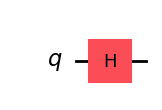

In [ ]:


qc.draw("mpl")



State probabilities: {np.str_('0'): np.float64(0.4999999999999999), np.str_('1'): np.float64(0.4999999999999999)}


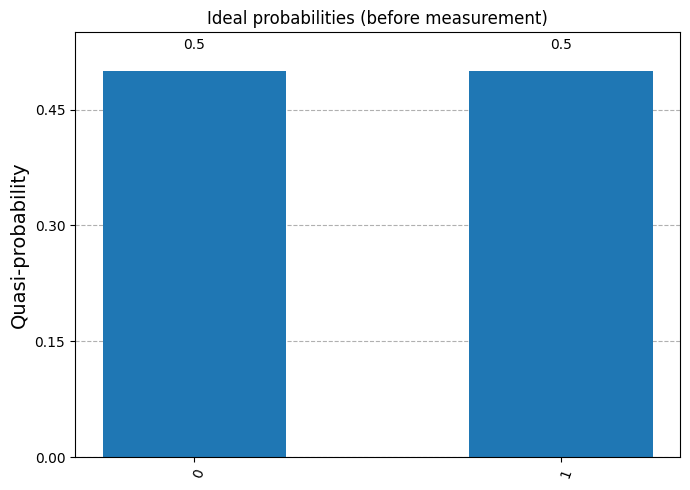

In [ ]:
state = Statevector(qc)
probabilities = state.probabilities_dict()
print("State probabilities:", probabilities)

plot_distribution(probabilities, title="Ideal probabilities (before measurement)")


In [ ]:


qc.measure_all()
print(qc.draw("text"))



        ┌───┐ ░ ┌─┐
     q: ┤ H ├─░─┤M├
        └───┘ ░ └╥┘
meas: 1/═════════╩═
                 0 


In [ ]:


simulator = AerSimulator()
compiled_circuit = transpile(qc, simulator)
job = simulator.run(compiled_circuit, shots=1024)
result = job.result()
counts = result.get_counts()

print("Measurement counts (1024 shots):", counts)



Measurement counts (1024 shots): {'0': 531, '1': 493}


Step 6: Plot the measurement histogram

You should see roughly 50% 0 and 50% 1, matching the ideal probabilities from Step 4.

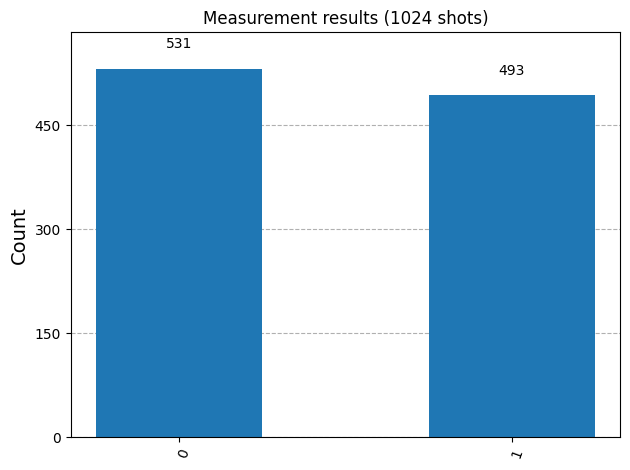

In [ ]:


plot_histogram(counts, title="Measurement results (1024 shots)")

